# K-Nearest Neighbors: Predicting Job Satisfaction (O*NET-linked subset only)

**Question:** Can a KNN classifier predict whether a college graduate is satisfied at work, and does adding person-job fit information improve on background factors alone?

**Data:** `notebooks/possible data integration/nscg2023_onet30_2_subset.csv`, the NSCG 2023 respondents in 25 reviewed occupations linked to O*NET 30.2 Work Values. Nothing else is loaded.

**Target:** `not_satisfied` = 1 if the person is somewhat or very dissatisfied with their job (`JOBSATIS` 3 or 4), 0 if satisfied. The model focuses on the minority group we actually want to find. ROC AUC is the same either way.

**Leakage rule:** satisfaction-with-each-aspect columns are never used as features. They are almost the same question as overall satisfaction.

## Summary

| Model | Test ROC AUC (95% CI) | ΔAUC vs. baseline (95% CI) |
|---|---|---|
| A. Baseline | 0.617 [0.567, 0.667] | |
| B. + personal work values | 0.577 [0.524, 0.632] | −0.040 [−0.094, +0.013] |
| C. + occupation profile | 0.562 [0.508, 0.617] | −0.055 [−0.108, −0.005] |
| D. + fit features | 0.562 [0.506, 0.620] | −0.055 [−0.113, −0.001] |

- **KNN is weak on this subset.** The best model is the baseline, at AUC 0.62. That's better than chance but not by much.
- **Adding columns made KNN worse, not better.** Personal values, the O*NET profile, and the fit gaps all lowered test AUC. For C and D the drop is just outside zero.
- **Fit adds nothing beyond the occupation:** D vs. C is +0.001 [−0.021, +0.022].
- **This is mainly a KNN problem, not proof that fit doesn't matter.** KNN gives every standardized column an equal vote in the distance. With 6,849 people, 25 occupations, and 124 dissatisfied people in the test set, extra columns mostly add noise. A model that learns weights (logistic regression, trees) is a fairer test.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
N_BOOT = 2000                      # bootstrap resamples for confidence intervals
K_GRID = [15, 51, 101, 201, 401, 601, 801, 1201]

# Finds the subset file whether this notebook sits next to it, in notebooks/, or anywhere in the team repo.
FILE = 'nscg2023_onet30_2_subset.csv'
_here = [Path.cwd(), *Path.cwd().parents]
_places = [p / sub for p in _here for sub in ['', 'possible data integration', 'notebooks/possible data integration']]
SUBSET = next(p / FILE for p in _places if (p / FILE).exists())
RESULTS = Path.cwd() / 'results'
RESULTS.mkdir(exist_ok=True)

ASPECTS = ['ADV', 'BEN', 'CHAL', 'IND', 'LOC', 'RESP', 'SAL', 'SEC', 'SOC']
NUM_BASE = ['AGE']                                               # salary and hours are not in the subset
CAT_BASE = ['SEX_2023', 'DGRDG', 'OCEDRLP', 'SUPWK', 'WAPRI']   # WAPRI = primary work activity; race, sector, size, married are not in the subset
IMP = [f'imp_{a}' for a in ASPECTS]          # personal work values: 4 = very important ... 1 = not important
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 2. Helper functions

KNN is distance based, so every numeric feature is standardized and every categorical feature is one-hot encoded inside a pipeline. The scaler is fit on training folds only, so no information leaks from the test set.

For each feature set we:
1. Hold out a stratified 20% test set (same split for every model, so comparisons are paired).
2. Tune `k` and the neighbor weighting with 5-fold stratified cross-validation on the training set, scoring by ROC AUC.
3. Pick a decision threshold from out-of-fold training predictions (the one that maximizes F1 for the not-satisfied class). The test set is never used to choose anything.
4. Report test ROC AUC with a 95% bootstrap confidence interval, survey-weighted AUC, PR AUC, and precision / recall / F1 for the not-satisfied class.

In [2]:
def make_pipeline(num, cat):
    pre = ColumnTransformer([('num', StandardScaler(), num),
                             ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
    return Pipeline([('pre', pre), ('knn', KNeighborsClassifier(n_jobs=-1))])


def fit_knn(data, y, train_idx, num, cat, k_grid=K_GRID):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    search = GridSearchCV(make_pipeline(num, cat),
                          {'knn__n_neighbors': k_grid, 'knn__weights': ['uniform', 'distance']},
                          scoring='roc_auc', cv=cv, n_jobs=1)
    search.fit(data.loc[train_idx], y[train_idx])
    # threshold from out-of-fold training predictions (never from the test set)
    oof = cross_val_predict(search.best_estimator_, data.loc[train_idx], y[train_idx],
                            cv=cv, method='predict_proba')[:, 1]
    grid = np.unique(np.round(oof, 4))
    f1s = [precision_recall_fscore_support(y[train_idx], oof >= t, average='binary', zero_division=0)[2] for t in grid]
    search.threshold_ = float(grid[int(np.argmax(f1s))])
    return search


def bootstrap_auc(y_true, p, rng):
    y_true, p = np.asarray(y_true), np.asarray(p)
    out = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].min() != y_true[i].max():
            out.append(roc_auc_score(y_true[i], p[i]))
    return np.percentile(out, [2.5, 97.5])


def evaluate(name, search, data, y, w, test_idx):
    p = search.predict_proba(data.loc[test_idx])[:, 1]
    yt = y[test_idx].to_numpy()
    lo, hi = bootstrap_auc(yt, p, np.random.default_rng(SEED))
    pred = (p >= search.threshold_).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(yt, pred, average='binary', zero_division=0)
    row = {'model': name,
           'best k': search.best_params_['knn__n_neighbors'],
           'weights': search.best_params_['knn__weights'],
           'CV AUC': round(search.best_score_, 3),
           'test AUC': round(roc_auc_score(yt, p), 3),
           'AUC 95% CI': f'[{lo:.3f}, {hi:.3f}]',
           'weighted AUC': round(roc_auc_score(yt, p, sample_weight=w[test_idx]), 3),
           'PR AUC': round(average_precision_score(yt, p), 3),
           'threshold': round(search.threshold_, 3),
           'precision': round(prec, 3), 'recall': round(rec, 3), 'F1': round(f1, 3)}
    return row, p


def paired_delta_auc(y_true, p_base, p_new, label):
    rng = np.random.default_rng(SEED)
    y_true = np.asarray(y_true)
    d = []
    for _ in range(N_BOOT):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].min() != y_true[i].max():
            d.append(roc_auc_score(y_true[i], p_new[i]) - roc_auc_score(y_true[i], p_base[i]))
    d = np.array(d)
    point = roc_auc_score(y_true, p_new) - roc_auc_score(y_true, p_base)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {'comparison': label, 'ΔAUC': round(point, 3), '95% CI': f'[{lo:+.3f}, {hi:+.3f}]',
            'share of bootstraps > 0': round((d > 0).mean(), 3)}


def plot_k_curves(searches, title):
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, s in searches.items():
        r = pd.DataFrame(s.cv_results_)
        r = r[r.param_knn__weights == s.best_params_['knn__weights']]
        ax.errorbar(r.param_knn__n_neighbors.astype(int), r.mean_test_score, yerr=r.std_test_score,
                    marker='o', capsize=3, label=f"{name} ({s.best_params_['knn__weights']})")
    ax.set_xlabel('k (number of neighbors)'); ax.set_ylabel('5-fold CV ROC AUC')
    ax.set_title(title); ax.legend(frameon=False, fontsize=9)
    plt.tight_layout(); plt.show()

## 3. O*NET-linked subset (25 occupations)

This notebook uses only `nscg2023_onet30_2_subset.csv`. Nothing is merged in from `nscg2023_clean.csv`, so the baseline uses only the background columns the subset has: age, sex, highest degree, degree relatedness, supervisor, and primary work activity (`WAPRI`). Salary, hours, race/ethnicity, employer sector and size, and marital status are not in this file.

In [3]:
onet = pd.read_csv(SUBSET, low_memory=False)
onet = onet[onet['JOBSATIS'].isin([1, 2, 3, 4])].reset_index(drop=True)   # keep valid answers only

# JOBSATIS: 1 very satisfied, 2 somewhat satisfied, 3 somewhat dissatisfied, 4 very dissatisfied
onet['not_satisfied'] = (onet['JOBSATIS'] >= 3).astype(int)
for a in ASPECTS:
    onet[f'imp_{a}'] = 5 - onet[f'FAC{a}']                     # same recoding as the EDA notebook: 4 = very important
for c in CAT_BASE:
    onet[c] = onet[c].astype(str)

y_on = onet['not_satisfied']
w_on = onet['WTSURVY']
print(f'loaded {SUBSET.name}: {len(onet):,} people, {y_on.mean():.1%} not satisfied, '
      f'{onet.ONET_SOC_CODE.nunique()} occupations')

loaded nscg2023_onet30_2_subset.csv: 6,849 people, 9.0% not satisfied, 25 occupations


### 3.1 Fit features

O*NET rates what each occupation offers on six work values. NSCG asks how important nine job aspects are to the person. Following the mapping table in the NSCG EDA notebook (Section 9), each person's importance is averaged onto the O*NET value it matches. Both sides are rescaled to 0 to 1:

| O*NET work value | NSCG importance items |
|---|---|
| Achievement | intellectual challenge (`CHAL`) |
| Working Conditions | salary, benefits, job security (`SAL`, `BEN`, `SEC`) |
| Recognition | advancement (`ADV`) |
| Independence | independence, responsibility (`IND`, `RESP`) |
| Relationships | contribution to society (`SOC`) |

Support has no NSCG item and location has no O*NET value, so neither gets a gap. **This mapping is one reasonable choice for illustration. The team still needs to agree on its fit-scoring method.**

For each value, `gap = person importance − occupation level`. A positive gap means the job offers less than the person wants. `mean_abs_gap` sums up overall misfit.

In [4]:
ONET_WV = ['achievement', 'working_conditions', 'recognition', 'relationships', 'support', 'independence']
ONET_COLS = [f'ONET_WV_{v}' for v in ONET_WV]
MAP = {'achievement': ['CHAL'], 'working_conditions': ['SAL', 'BEN', 'SEC'],
       'recognition': ['ADV'], 'independence': ['IND', 'RESP'], 'relationships': ['SOC']}

GAPS = []
for value, items in MAP.items():
    person = (onet[[f'imp_{a}' for a in items]].mean(axis=1) - 1) / 3      # 1-4  -> 0-1
    job = (onet[f'ONET_WV_{value}'] - 1) / 6                                 # 1-7  -> 0-1
    onet[f'gap_{value}'] = person - job
    GAPS.append(f'gap_{value}')
onet['mean_abs_gap'] = onet[GAPS].abs().mean(axis=1)
FIT = GAPS + ['mean_abs_gap']
onet[FIT].describe().round(3)

,gap_achievement,gap_working_conditions,gap_recognition,gap_independence,gap_relationships,mean_abs_gap
count,6849.000,6849.000,6849.000,6849.000,6849.000,6849.000
mean,0.141,0.163,0.136,0.130,0.228,0.233
std,0.221,0.164,0.261,0.206,0.290,0.094
min,-0.833,-0.805,-0.833,-0.833,-0.833,0.022
25%,0.000,0.083,-0.055,0.000,0.112,0.166
50%,0.222,0.167,0.167,0.167,0.222,0.223
75%,0.278,0.278,0.333,0.278,0.445,0.289
max,0.583,0.570,0.667,0.612,0.833,0.700


### 3.2 Models

- **A. Baseline**: age, sex, degree, relatedness, supervisor, primary work activity
- **B. + personal values** (`imp_*`)
- **C. + occupation profile**: B plus the six O*NET work values
- **D. + fit features**: C plus the five gaps and `mean_abs_gap`

With only 25 occupations, the O*NET columns take just 25 distinct value combinations, so in C they mostly act as an occupation identifier. D tests whether the person-versus-job comparison adds anything beyond that.

In [5]:
train_o, test_o = train_test_split(onet.index, test_size=0.2, stratify=y_on, random_state=SEED)
print(f'train {len(train_o):,}  test {len(test_o):,}  (test has {int(y_on[test_o].sum())} not-satisfied people)')

K_GRID_SMALL = [15, 31, 51, 101, 151, 201, 301, 401, 601]
sets_on = {'A. Baseline': (NUM_BASE, CAT_BASE),
           'B. + personal values': (NUM_BASE + IMP, CAT_BASE),
           'C. + occupation profile': (NUM_BASE + IMP + ONET_COLS, CAT_BASE),
           'D. + fit features': (NUM_BASE + IMP + ONET_COLS + FIT, CAT_BASE)}
search_on, rows_on, probs_on = {}, [], {}
for name, (num, cat) in sets_on.items():
    search_on[name] = fit_knn(onet, y_on, train_o, num, cat, K_GRID_SMALL)
    row, probs_on[name] = evaluate(name, search_on[name], onet, y_on, w_on, test_o)
    rows_on.append(row)
res_on = pd.DataFrame(rows_on).set_index('model')
res_on

train 5,479  test 1,370  (test has 124 not-satisfied people)


,best k,weights,CV AUC,test AUC,AUC 95% CI,weighted AUC,PR AUC,threshold,precision,recall,F1
model,,,,,,,,,,,
A. Baseline,601,uniform,0.581,0.617,"[0.567, 0.667]",0.584,0.135,0.080,0.112,0.734,0.195
B. + personal values,201,uniform,0.597,0.577,"[0.524, 0.632]",0.604,0.120,0.090,0.124,0.387,0.188
C. + occupation profile,601,distance,0.592,0.562,"[0.508, 0.617]",0.533,0.114,0.084,0.104,0.387,0.164
D. + fit features,601,distance,0.595,0.562,"[0.506, 0.620]",0.510,0.116,0.079,0.110,0.565,0.185


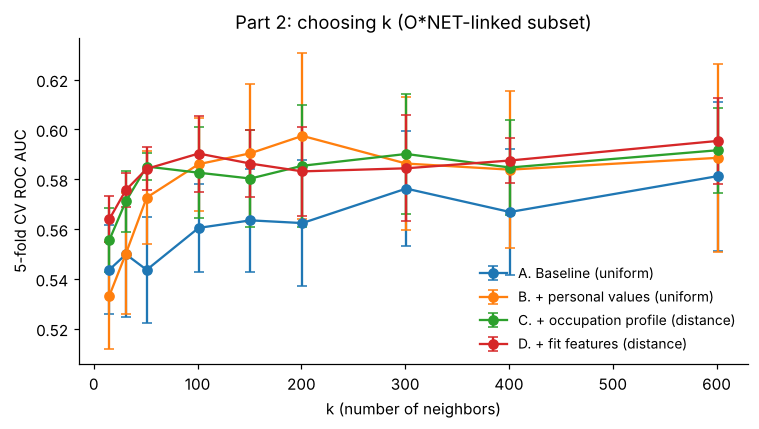

,ΔAUC,95% CI,share of bootstraps > 0
comparison,,,
B vs A,-0.040,"[-0.094, +0.013]",0.073
C vs A,-0.055,"[-0.108, -0.005]",0.012
D vs A,-0.055,"[-0.113, -0.001]",0.023
D vs C: fit beyond occupation,0.001,"[-0.021, +0.022]",0.522


In [6]:
plot_k_curves(search_on, 'Part 2: choosing k (O*NET-linked subset)')
yt = y_on[test_o].to_numpy()
names = list(sets_on)
deltas_on = pd.DataFrame([paired_delta_auc(yt, probs_on[names[0]], probs_on[n], f'{n[:1]} vs A') for n in names[1:]] +
                         [paired_delta_auc(yt, probs_on[names[2]], probs_on[names[3]], 'D vs C: fit beyond occupation')]
                        ).set_index('comparison')
deltas_on

**Observation:** The test set has only 124 not-satisfied people, so every confidence interval is about ±0.05 wide. CV and test also disagree: on CV, B to D score slightly above A (0.59–0.60 vs. 0.58), but on the test set they are lower. Read the small differences as noise, and the overall pattern as "the extra columns don't help KNN." D vs. C, the actual fit question, is +0.001, so there's no detectable effect.

## 4. Where the best model makes mistakes

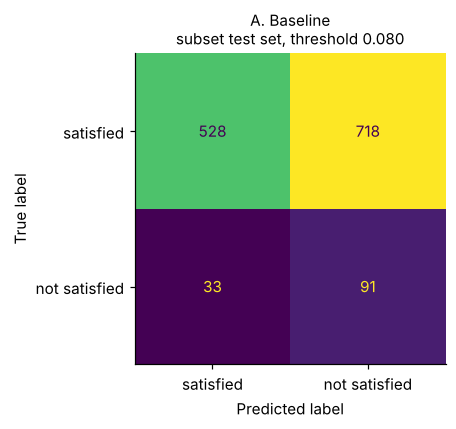

In [7]:
best_name = res_on['test AUC'].idxmax()
s = search_on[best_name]
pred = (probs_on[best_name] >= s.threshold_).astype(int)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(y_on[test_o], pred),
                       display_labels=['satisfied', 'not satisfied']).plot(ax=ax, colorbar=False, values_format=',')
ax.set_title(f'{best_name}\nsubset test set, threshold {s.threshold_:.3f}', fontsize=10)
plt.tight_layout(); plt.show()

**Observation:** The best model (baseline) uses a low threshold (0.080), so it catches about 73% of the not-satisfied people in the test set (about 91 of 124). The cost is many false alarms: precision is 11%, only slightly above the 9% base rate. That's useful for ranking who might be at risk, not for labeling individuals.

## 5. Save results

In [8]:
res_on.to_csv(RESULTS / 'knn_subset_results.csv')
print('saved', RESULTS / 'knn_subset_results.csv')
res_on

saved /home/claude/break-through-tech/swytch-2d-predicting-job-satisfaction-from-person-job-fit/notebooks/results/knn_subset_results.csv


,best k,weights,CV AUC,test AUC,AUC 95% CI,weighted AUC,PR AUC,threshold,precision,recall,F1
model,,,,,,,,,,,
A. Baseline,601,uniform,0.581,0.617,"[0.567, 0.667]",0.584,0.135,0.080,0.112,0.734,0.195
B. + personal values,201,uniform,0.597,0.577,"[0.524, 0.632]",0.604,0.120,0.090,0.124,0.387,0.188
C. + occupation profile,601,distance,0.592,0.562,"[0.508, 0.617]",0.533,0.114,0.084,0.104,0.387,0.164
D. + fit features,601,distance,0.595,0.562,"[0.506, 0.620]",0.510,0.116,0.079,0.110,0.565,0.185


## 6. Takeaways and next steps

**For the team write-up:**
- On the O*NET-linked subset alone, KNN reaches a test AUC of 0.617 [0.567, 0.667] using only background factors.
- Personal work values, the O*NET occupation profile, and the gap-based fit features did not improve KNN, and C and D did slightly worse.
- Fit beyond the occupation profile: ΔAUC +0.001 [−0.021, +0.022].

**Limitations:**
- Only 25 occupations, and the O*NET Work Values ratings mostly date from 2008.
- This file has no salary, hours, race/ethnicity, employer sector or size, or marital status, so the baseline is weaker than one built on the full NSCG file.
- The fit score uses one mapping of NSCG items onto O*NET values (Section 3.1).
- KNN can't use survey weights in training, and every column gets equal weight in the distance.

**Next steps:**
1. Run logistic regression and a tree model on the same split (same `SEED`) to see whether fit carries signal once features can be weighted.
2. Try KNN with a small feature set, such as baseline plus `mean_abs_gap` only.